# Project Data Mining — DBLP

**Conference Popularity and Association Pattern Mining**  
Jalankan sel berurutan. Notebook ini dibagi menurut Task 1–6, bagian E (temporal), dan kesimpulan.

**Sumber:** [snapshot bulanan DBLP](https://dblp.org/xml/release/) dan [panduan format XML](https://dblp.org/faq/16154937.html). Simpan berkas snapshot `.xml.gz` dan `dblp.dtd` dari rilis yang sama di `data/raw/`. Catat DOI/URL snapshot dan tanggal pengambilan pada konfigurasi. Snapshot bulanan dipilih agar eksperimen dapat diulang. File XML penuh besar; siapkan ruang disk dan RAM yang cukup.

**Asumsi:** `inproceedings` mencakup paper konferensi dan workshop. `year` pada record ini adalah tahun acara konferensi menurut DBLP, sehingga tren di sini mengikuti tahun acara. Nama penulis DBLP dinormalkan secara konservatif; nama yang tampak sama belum tentu orang yang sama. Popularitas berarti aktivitas publikasi, bukan mutu atau prestise venue.

**Dependensi** (jalankan sekali pada environment notebook): `pip install lxml pandas numpy scipy matplotlib mlxtend`.

In [5]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import gzip, json, re, shutil, sqlite3, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lxml import etree
from scipy.sparse import csr_matrix
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import mlxtend

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
for p in (RAW, OUT, RESULTS): p.mkdir(parents=True, exist_ok=True)

SNAPSHOT_GZ = RAW / "dblp.xml.gz"  # ganti jika nama file berbeda
DTD = RAW / "dblp.dtd"
SNAPSHOT_URL = "https://dblp.org/xml/dblp.xml.gz"  # sumber snapshot yang diunduh
DOWNLOAD_DATE = "2026-11-19"  # tanggal unduh
YEAR_MIN, YEAR_MAX = 2015, 2025
SUPPORTS = [0.001, 0.005, 0.01, 0.02]
MIN_CONFIDENCE = 0.50

TEMPORAL_SUPPORT = 0.005  # sama untuk setiap periode; catat jika diubah
VENUE_ALIASES = {}  # contoh: {"Nama Lama": "Nama Kanonis"}; isi setelah audit

assert SNAPSHOT_GZ.exists(), f"Unduh snapshot DBLP ke {SNAPSHOT_GZ}"
assert DTD.exists(), f"Simpan dblp.dtd di {DTD}"
assert SNAPSHOT_URL and DOWNLOAD_DATE, "Isi SNAPSHOT_URL dan DOWNLOAD_DATE untuk reproduksibilitas"
print("Snapshot:", SNAPSHOT_URL, "| diambil:", DOWNLOAD_DATE)
print("Ukuran gzip (GB):", round(SNAPSHOT_GZ.stat().st_size / 1e9, 2))

Snapshot: https://dblp.org/xml/dblp.xml.gz | diambil: 2026-11-19
Ukuran gzip (GB): 1.12


## Task 1 — Data Understanding and Preprocessing

Alur: dekompresi snapshot → baca XML secara streaming → filter tahun dan `inproceedings` → validasi atribut → normalisasi konservatif → deduplikasi kunci DBLP → simpan ke SQLite. SQLite menghindari memuat semua metadata publikasi sekaligus ke RAM. File `.xml` hasil dekompresi dapat berukuran beberapa GB.

In [6]:
XML = RAW / "dblp.xml"
if not XML.exists():
    print("Mendekompresi snapshot; ini dapat memakan waktu...")
    with gzip.open(SNAPSHOT_GZ, "rb") as src, XML.open("wb") as dst:
        shutil.copyfileobj(src, dst, length=8 * 1024 * 1024)
print("XML (GB):", round(XML.stat().st_size / 1e9, 2))

def clean_text(value):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", value or "")).strip()

def field(el, tag):
    child = el.find(tag)
    return clean_text("".join(child.itertext())) if child is not None else ""

def normalize_author(value):
    # Pertahankan suffix disambiguasi DBLP; jangan gabungkan orang berbeda secara agresif.
    return clean_text(value)

def normalize_venue(value):
    name = clean_text(value)
    return VENUE_ALIASES.get(name, name)

DB = OUT / "dblp_2015_2025.sqlite"
if DB.exists():
    print("Database sudah ada. Hapus/rename secara manual bila ingin ekstraksi ulang:", DB)
else:
    con = sqlite3.connect(DB)
    con.executescript("""
        CREATE TABLE publications (dblp_key TEXT PRIMARY KEY, title TEXT NOT NULL, year INTEGER NOT NULL, venue TEXT NOT NULL);
        CREATE TABLE authorship (dblp_key TEXT NOT NULL, author TEXT NOT NULL, PRIMARY KEY (dblp_key, author));
        CREATE TABLE audit (reason TEXT PRIMARY KEY, n INTEGER NOT NULL);
    """)
    audit = Counter()
    type_counts = Counter()
    pending_pub, pending_auth = [], []
    context = etree.iterparse(str(XML), events=("end",), load_dtd=True, resolve_entities=True, no_network=True, huge_tree=True)
    for _, el in context:
        if el.getparent() is None or el.getparent().tag != "dblp":
            continue
        type_counts[el.tag] += 1
        if el.tag == "inproceedings":
            audit["inproceedings_raw"] += 1
            year_raw = field(el, "year")
            if not year_raw.isdigit() or not YEAR_MIN <= int(year_raw) <= YEAR_MAX:
                audit["excluded_year"] += 1
            else:
                key = clean_text(el.get("key"))
                title = field(el, "title")
                venue = normalize_venue(field(el, "booktitle"))
                authors = sorted({normalize_author("".join(a.itertext())) for a in el.findall("author")})
                authors = [a for a in authors if a]
                if not key or not title or not venue or not authors:
                    audit["excluded_missing_key_title_venue_or_author"] += 1
                else:
                    pending_pub.append((key, title, int(year_raw), venue))
                    pending_auth.extend((key, a) for a in authors)
                    audit["eligible_before_dedup"] += 1
        if len(pending_pub) >= 10000:
            before = con.total_changes
            con.executemany("INSERT OR IGNORE INTO publications VALUES (?,?,?,?)", pending_pub)
            audit["inserted_publications"] += con.total_changes - before
            con.executemany("INSERT OR IGNORE INTO authorship VALUES (?,?)", pending_auth)
            con.commit()
            pending_pub.clear(); pending_auth.clear()
        el.clear()
        while el.getprevious() is not None:
            del el.getparent()[0]
    before = con.total_changes
    con.executemany("INSERT OR IGNORE INTO publications VALUES (?,?,?,?)", pending_pub)
    audit["inserted_publications"] += con.total_changes - before
    con.executemany("INSERT OR IGNORE INTO authorship VALUES (?,?)", pending_auth)
    audit["duplicate_keys"] = audit["eligible_before_dedup"] - audit["inserted_publications"]
    con.executemany("INSERT INTO audit VALUES (?,?)", list(audit.items()))
    con.execute("CREATE INDEX idx_auth_author ON authorship(author)")
    con.execute("CREATE INDEX idx_pub_year ON publications(year)")
    con.commit(); con.close()
    (RESULTS / "record_types.json").write_text(json.dumps(type_counts, indent=2), encoding="utf-8")
    print("Ekstraksi selesai:", dict(audit))

con = sqlite3.connect(DB)
print("Tipe record pada XML:")
display(pd.Series(json.loads((RESULTS / "record_types.json").read_text()), name="jumlah").sort_values(ascending=False))
display(pd.read_sql_query("SELECT * FROM audit ORDER BY reason", con))
display(pd.read_sql_query("SELECT * FROM publications LIMIT 5", con))

XML (GB): 5.41
Database sudah ada. Hapus/rename secara manual bila ingin ekstraksi ulang: /Users/hello/Documents/Folder Surya/Kuliah/Semester 7/Penambangan Data/Tugas Besar Data Mining/data/processed/dblp_2015_2025.sqlite
Tipe record pada XML:


article          4527388
www              4247510
inproceedings    4004309
phdthesis         158395
incollection       71264
proceedings        65903
data               31529
book               21654
mastersthesis         27
Name: jumlah, dtype: int64

,reason,n
0,duplicate_keys,0
1,eligible_before_dedup,2001757
2,excluded_missing_key_title_venue_or_author,2445
3,excluded_year,2000107
4,inproceedings_raw,4004309
5,inserted_publications,2001757


,dblp_key,title,year,venue
0,conf/dac/RoquetSRTSK24,Cross-Layer Reliability Evaluation and Efficie...,2024,DAC
1,conf/dac/LiuZWCYHYJ22,SATO: spiking neural network acceleration via ...,2022,DAC
2,conf/dac/AhnYLHKP20,Hawkware: Network Intrusion Detection based on...,2020,DAC
3,conf/dac/ParkPVC24,Accelerating DTCO with a Sample-Efficient Acti...,2024,DAC
4,conf/dac/PuL0HLC024,Lesyn: Placement-aware Logic Resynthesis for N...,2024,DAC


,publications,unique_authors,unique_venues
0,2001757,1822585,8903


,year,publications
0,2015,161391
1,2016,162280
2,2017,168202
3,2018,176723
4,2019,188881
5,2020,172122
6,2021,178521
7,2022,178453
8,2023,201801
9,2024,213690


,venue,publications
0,NeurIPS,23358
1,ICASSP,21126
2,IGARSS,19688
3,AAAI,18413
4,CVPR,17435
5,EMBC,14679
6,ICML,13617
7,IROS,12834
8,ICRA,12362
9,CDC,11666


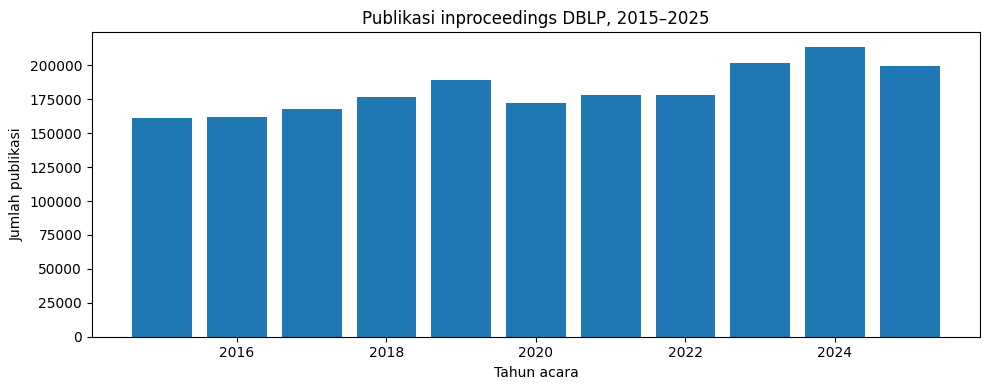

In [7]:
stats = pd.read_sql_query("""
SELECT
 (SELECT COUNT(*) FROM publications) AS publications,
 (SELECT COUNT(DISTINCT author) FROM authorship) AS unique_authors,
 (SELECT COUNT(DISTINCT venue) FROM publications) AS unique_venues
""", con)
by_year = pd.read_sql_query("SELECT year, COUNT(*) AS publications FROM publications GROUP BY year ORDER BY year", con)
by_venue = pd.read_sql_query("SELECT venue, COUNT(*) AS publications FROM publications GROUP BY venue ORDER BY publications DESC, venue", con)
display(stats, by_year, by_venue.head(20))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.year, by_year.publications)
ax.set(xlabel="Tahun acara", ylabel="Jumlah publikasi", title="Publikasi inproceedings DBLP, 2015–2025")
plt.tight_layout(); plt.show()
stats.to_csv(RESULTS / "task1_stats.csv", index=False)
by_year.to_csv(RESULTS / "task1_by_year.csv", index=False)
by_venue.to_csv(RESULTS / "task1_by_venue.csv", index=False)

**Catatan interpretasi Task 1:** jelaskan alasan setiap pengecualian pada tabel audit. Audit nama venue yang tampak sinonim sebelum finalisasi `VENUE_ALIASES`; jika aturan alias diubah, ekstraksi harus dijalankan ulang. Keterbatasan penting: penggabungan penulis berdasarkan nama dapat menyatukan homonim atau memisahkan variasi nama orang yang sama.

## Task 2 — Conference Popularity Analysis

Jumlah publikasi dihitung per venue. Penulis unik dihitung per venue setelah join publikasi–authorship; seorang penulis dengan beberapa paper pada venue yang sama dihitung sekali.

,venue,publications
0,NeurIPS,25004
1,ICASSP,21126
2,IGARSS,19688
3,AAAI,18413
4,CVPR,17435
5,EMBC,14679
6,ICML,13617
7,IROS,12834
8,ICRA,12362
9,CDC,11666


,venue,unique_authors
0,NeurIPS,56073
1,AAAI,44604
2,ICASSP,41097
3,EMBC,39318
4,IGARSS,35229
5,CVPR,34970
6,ICML,31397
7,IROS,31200
8,IJCNN,29804
9,ICLR,28751


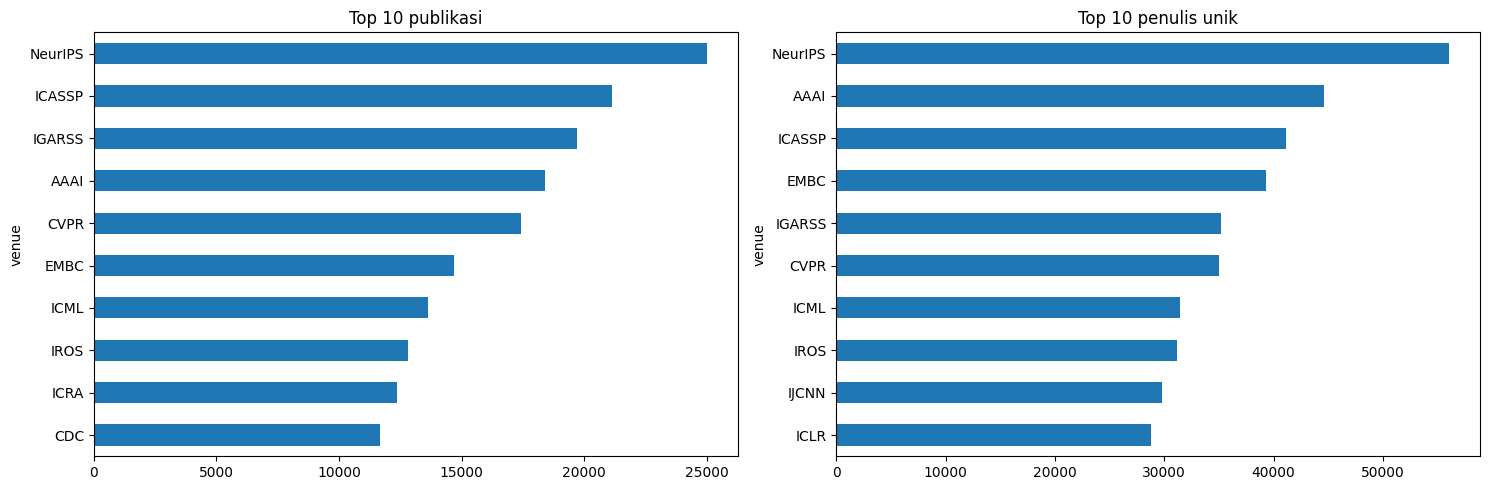

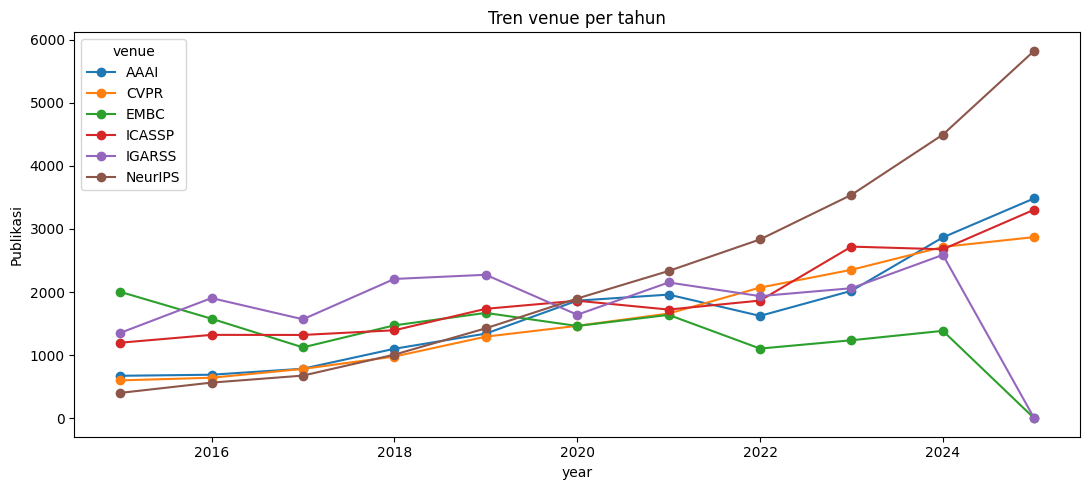

In [8]:
DB = OUT / "dblp_2015_2025.sqlite"
if not DB.exists():
    raise FileNotFoundError("Jalankan ekstraksi Task 1 terlebih dahulu agar database DBLP tersedia.")
if "con" not in globals():
    con = sqlite3.connect(DB)

# Samakan label historis NIPS dengan NeurIPS untuk ranking dan tren lintas tahun.
venue_expr = "CASE WHEN venue = 'NIPS' THEN 'NeurIPS' ELSE venue END"
pub_venue_expr = "CASE WHEN p.venue = 'NIPS' THEN 'NeurIPS' ELSE p.venue END"
top_pubs = pd.read_sql_query(f"""
SELECT {venue_expr} AS venue, COUNT(*) AS publications FROM publications
GROUP BY {venue_expr} ORDER BY publications DESC, venue LIMIT 10
""", con)
top_authors = pd.read_sql_query(f"""
SELECT {pub_venue_expr} AS venue, COUNT(DISTINCT a.author) AS unique_authors
FROM publications p JOIN authorship a USING (dblp_key)
GROUP BY {pub_venue_expr} ORDER BY unique_authors DESC, venue LIMIT 10
""", con)
display(top_pubs, top_authors)
top_pubs.to_csv(RESULTS / "task2_top_publications.csv", index=False)
top_authors.to_csv(RESULTS / "task2_top_authors.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_pubs.iloc[::-1].plot.barh(x="venue", y="publications", ax=axes[0], legend=False, title="Top 10 publikasi")
top_authors.iloc[::-1].plot.barh(x="venue", y="unique_authors", ax=axes[1], legend=False, title="Top 10 penulis unik")
plt.tight_layout(); plt.show()

leaders = tuple(dict.fromkeys(top_pubs.venue.head(5).tolist() + top_authors.venue.head(5).tolist()))
trend = pd.read_sql_query(f"SELECT year, {venue_expr} AS venue, COUNT(*) AS publications FROM publications GROUP BY year, {venue_expr}", con)
trend_pivot = trend[trend.venue.isin(leaders)].pivot(index="year", columns="venue", values="publications").fillna(0)
trend_pivot.plot(figsize=(11, 5), marker="o", title="Tren venue per tahun")
plt.ylabel("Publikasi"); plt.tight_layout(); plt.show()
trend.to_csv(RESULTS / "task2_trend_all_venues.csv", index=False)

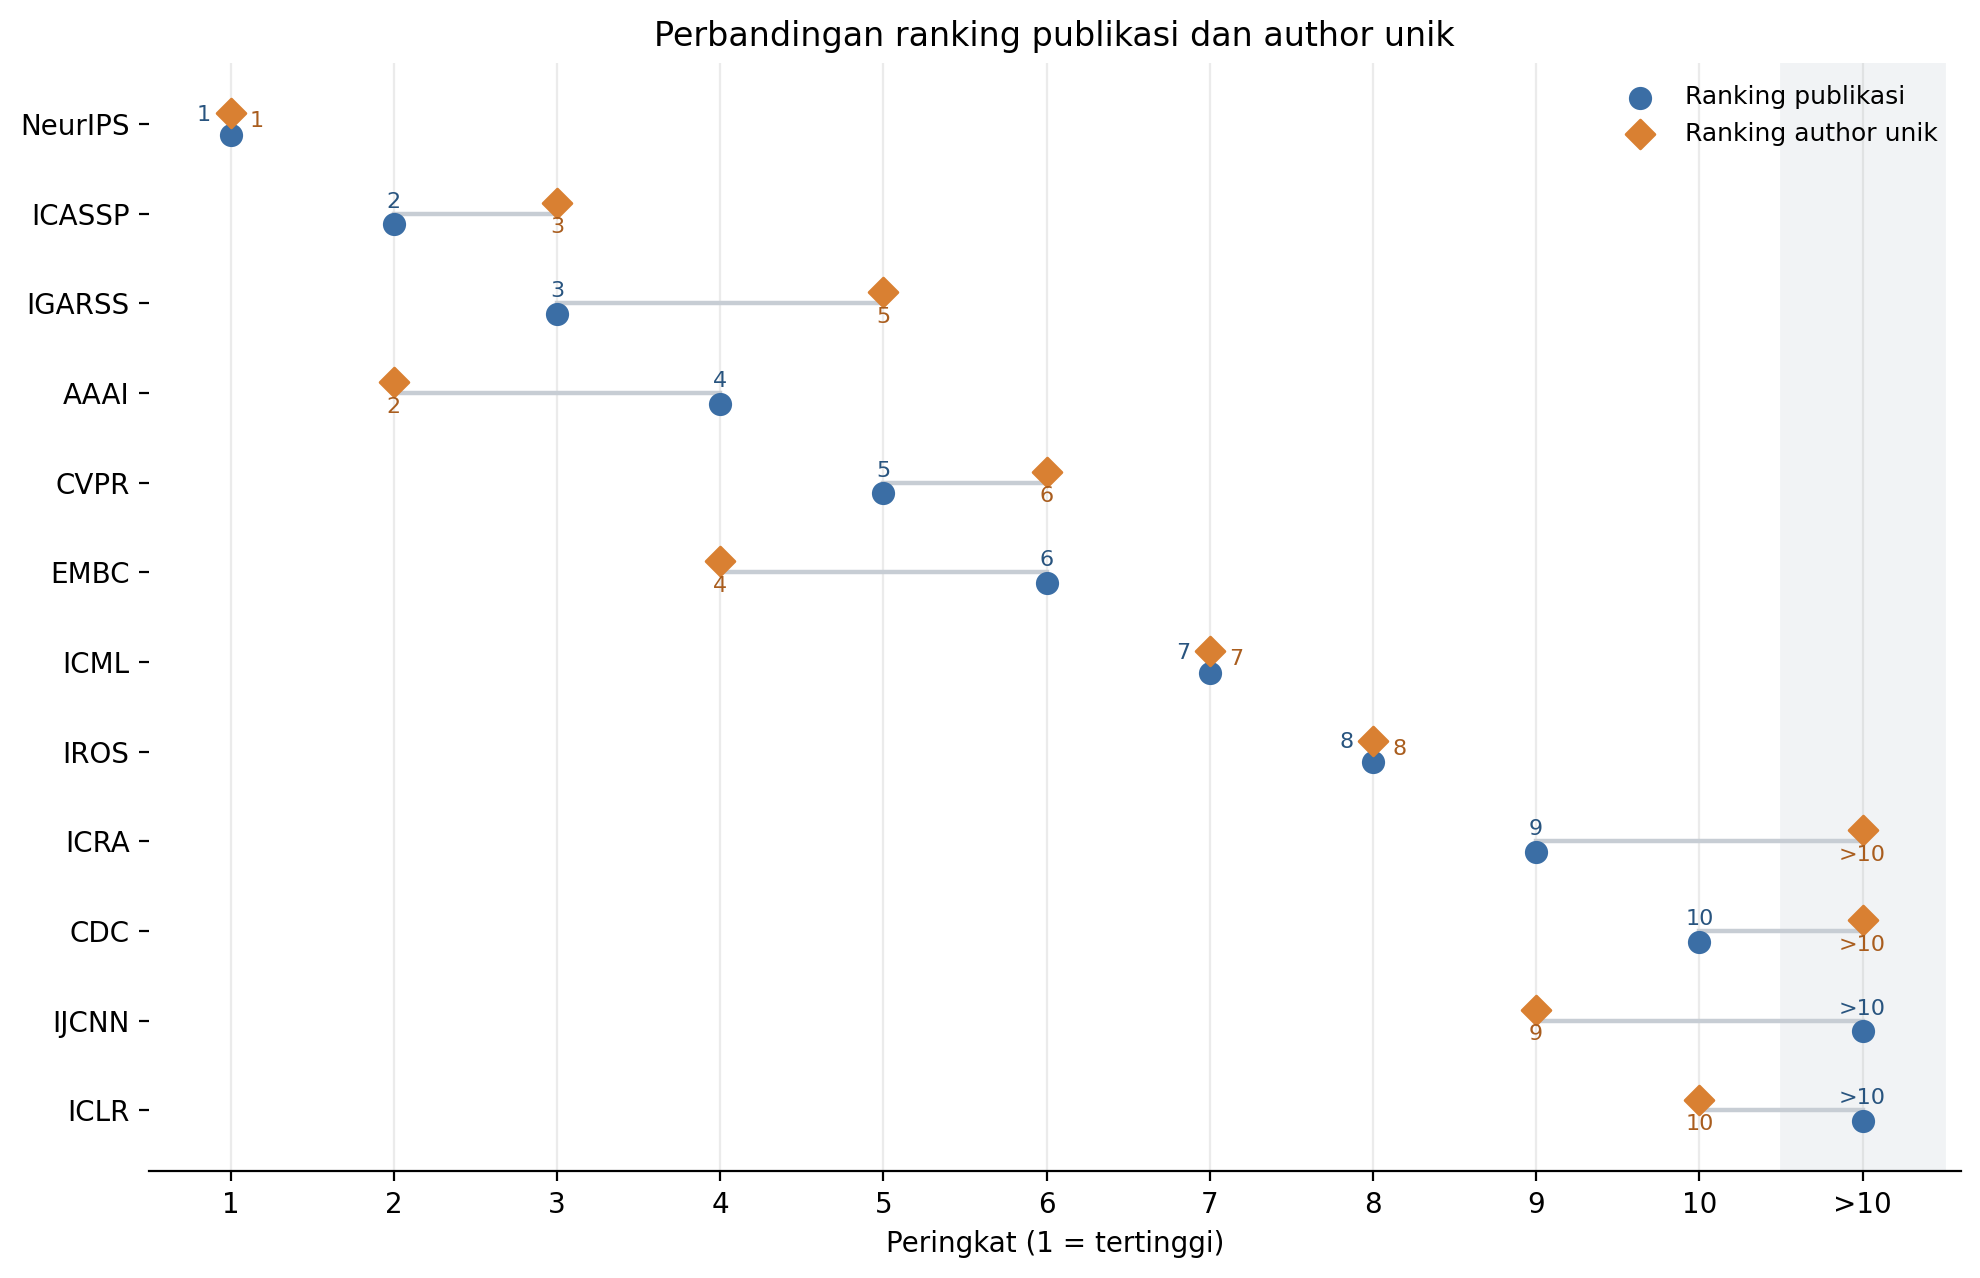

In [12]:
# Bandingkan posisi setiap venue pada dua ranking top 10.
pub_rank = pd.read_sql_query(f"""
WITH counts AS (
    SELECT {venue_expr} AS venue, COUNT(*) AS publications
    FROM publications GROUP BY {venue_expr}
)
SELECT venue, RANK() OVER (ORDER BY publications DESC) AS rank_publications
FROM counts
""", con)
author_rank = pd.read_sql_query(f"""
WITH counts AS (
    SELECT {pub_venue_expr} AS venue, COUNT(DISTINCT a.author) AS unique_authors
    FROM publications p JOIN authorship a USING (dblp_key)
    GROUP BY {pub_venue_expr}
)
SELECT venue, RANK() OVER (ORDER BY unique_authors DESC) AS rank_authors
FROM counts
""", con)
rank_comparison = pub_rank.merge(author_rank, on="venue")
rank_comparison = rank_comparison.loc[
    (rank_comparison["rank_publications"] <= 10) | (rank_comparison["rank_authors"] <= 10)
].sort_values(["rank_publications", "venue"]).reset_index(drop=True)
rank_comparison.to_csv(RESULTS / "task2_rank_comparison.csv", index=False)

# Posisi di luar top 10 ditampilkan sebagai >10, sesuai tabel perbandingan.
chart_rows = np.arange(len(rank_comparison))
pub_positions = rank_comparison["rank_publications"].clip(upper=11).to_numpy()
author_positions = rank_comparison["rank_authors"].clip(upper=11).to_numpy()
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axvspan(10.5, 11.5, color="#f1f3f5", zorder=0)
for i, (pub_rank_value, author_rank_value) in enumerate(zip(pub_positions, author_positions)):
    ax.plot([pub_rank_value, author_rank_value], [i, i], color="#c7cdd4", linewidth=1.6, zorder=1)
ax.scatter(pub_positions, chart_rows + 0.12, s=54, marker="o", color="#3b6ea5", label="Ranking publikasi", zorder=3)
ax.scatter(author_positions, chart_rows - 0.12, s=54, marker="D", color="#d98032", label="Ranking author unik", zorder=3)
for i, (pub_rank_value, author_rank_value) in enumerate(zip(pub_positions, author_positions)):
    pub_label = str(int(pub_rank_value)) if pub_rank_value <= 10 else ">10"
    author_label = str(int(author_rank_value)) if author_rank_value <= 10 else ">10"
    if pub_rank_value == author_rank_value:
        ax.annotate(pub_label, (pub_rank_value, i + 0.12), xytext=(-7, 5), textcoords="offset points", ha="right", fontsize=8, color="#28547f")
        ax.annotate(author_label, (author_rank_value, i - 0.12), xytext=(7, -5), textcoords="offset points", ha="left", fontsize=8, color="#a95d1e")
    else:
        ax.annotate(pub_label, (pub_rank_value, i + 0.12), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8, color="#28547f")
        ax.annotate(author_label, (author_rank_value, i - 0.12), xytext=(0, -11), textcoords="offset points", ha="center", fontsize=8, color="#a95d1e")
ax.set_yticks(chart_rows, rank_comparison["venue"])
ax.invert_yaxis()
ax.set_xticks(list(range(1, 11)) + [11], [str(rank) for rank in range(1, 11)] + [">10"])
ax.set_xlim(0.5, 11.6)
ax.set_xlabel("Peringkat (1 = tertinggi)")
ax.set_title("Perbandingan ranking publikasi dan author unik")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS / "task2_ranking_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


### Hasil dan perbandingan ranking

Setelah label historis `NIPS` disatukan dengan `NeurIPS`, **NeurIPS** menempati peringkat pertama pada kedua ukuran: **25.004 publikasi** dan **56.073 author unik** selama 2015–2025. Untuk jumlah publikasi, berikutnya adalah ICASSP (21.126), IGARSS (19.688), AAAI (18.413), dan CVPR (17.435). Untuk author unik, posisi berikutnya adalah AAAI (44.604), ICASSP (41.097), EMBC (39.318), dan IGARSS (35.229).

Sebanyak **8 dari 10 venue** muncul pada kedua ranking. ICRA dan CDC masuk sepuluh besar berdasarkan jumlah publikasi saja, sedangkan IJCNN dan ICLR masuk sepuluh besar berdasarkan author unik saja. Jadi, jumlah paper dan luas partisipasi author berkaitan, tetapi tidak menghasilkan urutan yang sama. Author unik dihitung dari nama setelah pembersihan teks; nama yang sama belum tentu orang yang sama, dan variasi nama bisa dihitung terpisah.

Grafik perbandingan menempatkan venue di luar sepuluh besar pada posisi `>10`.

### Tren publikasi 2015–2025

Pada venue utama, aktivitas publikasi secara umum meningkat, meskipun beberapa venue berfluktuasi dari tahun ke tahun. CVPR naik dari 601 publikasi pada 2015 menjadi 2.871 pada 2025. AAAI naik dari 674 menjadi 3.485, dengan penurunan pada 2022 sebelum meningkat kembali. ICASSP bertambah dari 1.198 pada 2015 menjadi 3.306 pada 2025, tetapi sempat turun pada 2024.

Setelah label historis disatukan, publikasi NeurIPS meningkat setiap tahun: 403 pada 2015, 566 pada 2016, 677 pada 2017, lalu mencapai 5.823 pada 2025. Grafik tren menggunakan label yang sudah digabung sehingga mencakup seluruh periode pengamatan.

Grafik juga menunjukkan tidak ada rekaman berlabel EMBC dan IGARSS pada 2025. Angka nol itu berarti tidak ada baris yang cocok dengan label tersebut pada data yang dianalisis; hal itu tidak cukup untuk menyimpulkan bahwa konferensinya berhenti menerbitkan paper. Cakupan dan konsistensi label pada snapshot DBLP perlu diperhitungkan.

### Kesimpulan

NeurIPS paling aktif berdasarkan jumlah publikasi dan author unik. Aktivitas beberapa venue besar meningkat sepanjang periode, sementara venue lain berubah-ubah. Ranking mengukur volume publikasi dan banyaknya nama author yang tercatat, bukan mutu atau prestise konferensi. Author unik dihitung berdasarkan nama yang sudah dibersihkan secara tekstual, sehingga belum sepenuhnya menyelesaikan masalah variasi nama atau homonim.

## Task 3 — Transactional Database Construction

Setiap item adalah nama venue yang sudah dinormalkan. Transaksi disimpan sebagai himpunan sehingga paper berulang di venue sama tidak menggandakan item. Representasi penulis merangkum seluruh periode; penulis–tahun mengukur ko-kemunculan pada tahun yang sama.

Author-based: {'transactions': 1822585, 'unique_items': 8903, 'mean_items': np.float64(2.8634159723689154), 'median_items': np.float64(1.0), 'max_items': np.int64(398)}
Author-year-based: {'transactions': 4088824, 'unique_items': 8903, 'mean_items': np.float64(1.6270191624780133), 'median_items': np.float64(1.0), 'max_items': np.int64(89)}


,author,items
0,"""Johann"" Sebastian Rudolph","(Description Logic, Theory Combination, and Al..."
1,'Anau Mesui,"(ICT4D (2),)"
2,'Yinka Oyerinde,"(CONF-IRM, ICT4D (1))"
3,(Sophy) Shu-Jiun Chen,"(Dublin Core Conference,)"
4,2077AI,"(NeurIPS,)"
5,A AMuskan Kouser,"(ICCCNT,)"
6,A Aadhishri,"(ICCCNT,)"
7,A Ahmed Ibrahim,"(PIMRC,)"
8,A Andrew Moses,"(ICDCS,)"
9,A AnithaRani,"(ICCCNT,)"


,author,year,items
0,"""Johann"" Sebastian Rudolph",2019,"(Description Logic, Theory Combination, and Al..."
1,'Anau Mesui,2019,"(ICT4D (2),)"
2,'Yinka Oyerinde,2019,"(CONF-IRM, ICT4D (1))"
3,(Sophy) Shu-Jiun Chen,2016,"(Dublin Core Conference,)"
4,2077AI,2025,"(NeurIPS,)"
5,A AMuskan Kouser,2024,"(ICCCNT,)"
6,A Aadhishri,2024,"(ICCCNT,)"
7,A Ahmed Ibrahim,2024,"(PIMRC,)"
8,A Andrew Moses,2024,"(ICDCS,)"
9,A AnithaRani,2024,"(ICCCNT,)"


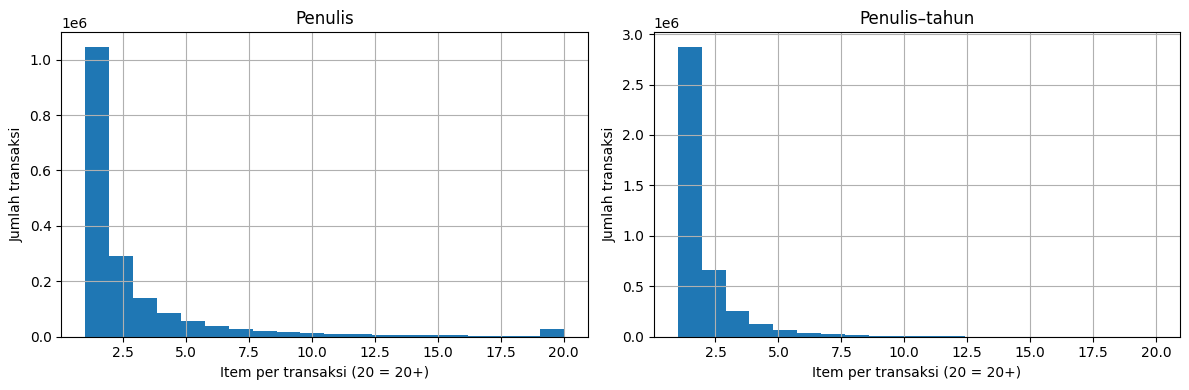

In [9]:
author_venue = pd.read_sql_query("""
SELECT DISTINCT a.author, p.venue FROM authorship a JOIN publications p USING (dblp_key)
ORDER BY a.author, p.venue
""", con)
author_year_venue = pd.read_sql_query("""
SELECT DISTINCT a.author, p.year, p.venue FROM authorship a JOIN publications p USING (dblp_key)
ORDER BY a.author, p.year, p.venue
""", con)
author_tx = author_venue.groupby("author", sort=False).venue.agg(lambda s: tuple(sorted(set(s)))).reset_index(name="items")
author_year_tx = author_year_venue.groupby(["author", "year"], sort=False).venue.agg(lambda s: tuple(sorted(set(s)))).reset_index(name="items")
del author_venue, author_year_venue

def transaction_summary(frame):
    sizes = frame["items"].map(len)
    return {"transactions": len(frame), "unique_items": len({x for row in frame["items"] for x in row}),
            "mean_items": sizes.mean(), "median_items": sizes.median(), "max_items": sizes.max()}


print("Author-based:", transaction_summary(author_tx))
print("Author-year-based:", transaction_summary(author_year_tx))
display(author_tx.head(10), author_year_tx.head(10))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, frame, title in zip(axes, [author_tx, author_year_tx], ["Penulis", "Penulis–tahun"]):
    frame["items"].map(len).clip(upper=20).hist(ax=ax, bins=20)
    ax.set(xlabel="Item per transaksi (20 = 20+)", ylabel="Jumlah transaksi", title=title)
plt.tight_layout(); plt.show()
author_tx.to_pickle(OUT / "author_transactions.pkl")
author_year_tx.to_pickle(OUT / "author_year_transactions.pkl")

**Interpretasi Task 3:** transaksi penulis dapat menangkap perpindahan topik/venue lintas tahun, tetapi menggabungkan publikasi yang jauh waktunya. Transaksi penulis–tahun memberi hubungan sezaman, namun sering lebih pendek dan menghasilkan lebih sedikit pasangan. Semua transaksi, termasuk yang hanya berisi satu item, tetap masuk penyebut support.

## Task 4 — Frequent Pattern Mining

Apriori dan FP-Growth diterapkan **secara terpisah** pada Author-Based Transactional Database yang sama. Minimum support adalah proporsi transaksi author yang memuat itemset. Setiap konfigurasi menampilkan jumlah frequent itemsets menurut ukuran 1, 2, 3, dan 4+; 10 itemset teratas secara keseluruhan; serta hingga 10 itemset teratas untuk ukuran 1, 2, dan 3. Daftar lengkap setiap konfigurasi disimpan sebagai CSV di `results/`.


In [ ]:
from collections import Counter
from math import ceil
from IPython.display import Markdown, display

# Build one-hot venue matrix from the Author-Based transactions.
def sparse_transactions(items, floor_support):
    n = len(items)
    if n == 0:
        raise ValueError("Tidak ada transaksi")
    counts = Counter(x for row in items for x in row)
    columns = sorted(x for x, count in counts.items() if count / n >= floor_support)
    index = {name: j for j, name in enumerate(columns)}
    rows, cols = [], []
    for i, basket in enumerate(items):
        for name in basket:
            j = index.get(name)
            if j is not None:
                rows.append(i)
                cols.append(j)
    matrix = csr_matrix((np.ones(len(rows), dtype=bool), (rows, cols)), shape=(n, len(columns)), dtype=bool)
    return pd.DataFrame.sparse.from_spmatrix(matrix, columns=columns)

author_matrix = sparse_transactions(author_tx["items"], min(SUPPORTS))
print(f"Author-Based matrix: {author_matrix.shape[0]:,} transaksi × {author_matrix.shape[1]:,} venue; {author_matrix.sparse.to_coo().nnz:,} item tercatat.")

# Keep the same result objects for Task 5 and Task 6.
mining = {}
summary = []

def itemset_view(frame, include_size=True, limit=10):
    view = frame.copy()
    view["Frequent itemset"] = view["itemsets"].map(lambda items: " | ".join(sorted(items)))
    view["Support (%)"] = view["support"] * 100
    view = view.sort_values(["support", "Frequent itemset"], ascending=[False, True]).head(limit)
    columns = ["Frequent itemset", "Support (%)"]
    if include_size:
        view["Ukuran"] = view["size"].astype(int)
        columns.append("Ukuran")
    return view[columns].reset_index(drop=True)

def report_configuration(algorithm, support, found):
    n_transactions = len(author_tx)
    minimum_count = ceil(support * n_transactions)
    size_counts = found["size"].value_counts()
    counts = pd.DataFrame({
        "Ukuran itemset": ["1-itemset", "2-itemset", "3-itemset", "4+ itemset"],
        "Jumlah yang memenuhi support": [
            int(size_counts.get(1, 0)), int(size_counts.get(2, 0)),
            int(size_counts.get(3, 0)), int((found["size"] >= 4).sum())
        ]
    })
    display(Markdown(f"#### {algorithm} — minimum support {support:.1%} (minimal {minimum_count:,} transaksi author)"))
    print(f"Total frequent itemsets: {len(found):,}")
    display(counts)
    display(Markdown("**10 frequent itemsets dengan support tertinggi (semua ukuran):**"))
    display(itemset_view(found, include_size=True, limit=10))
    for size in (1, 2, 3):
        part = found[found["size"] == size]
        display(Markdown(f"**Frequent {size}-itemsets:** {len(part):,} ditemukan; menampilkan hingga 10 teratas."))
        if part.empty:
            print(f"Tidak ada {size}-itemset yang memenuhi minimum support {support:.1%}.")
        else:
            display(itemset_view(part, include_size=False, limit=10))
    pairs = found[found["size"] == 2]
    if pairs.empty:
        print(f"Kombinasi conference yang memenuhi support {support:.1%}: tidak ada pasangan frequent.")
    else:
        best_pair = itemset_view(pairs, include_size=False, limit=1).iloc[0]
        n_pair = round(float(best_pair["Support (%)"]) / 100 * n_transactions)
        print(f"Pasangan paling sering: {best_pair['Frequent itemset']} — support {best_pair['Support (%)']:.3f}% (~{n_pair:,} transaksi author).")
    triples = found[found["size"] == 3]
    if triples.empty:
        print(f"Triple conference yang memenuhi support {support:.1%}: tidak ada.")
    else:
        best_triple = itemset_view(triples, include_size=False, limit=1).iloc[0]
        n_triple = round(float(best_triple["Support (%)"]) / 100 * n_transactions)
        print(f"Triple paling sering: {best_triple['Frequent itemset']} — support {best_triple['Support (%)']:.3f}% (~{n_triple:,} transaksi author).")

def save_run(algorithm, support, found, seconds):
    found = found.copy()
    found["size"] = found["itemsets"].map(len)
    mining[(algorithm, support)] = found
    size_counts = found["size"].value_counts()
    row = {
        "algorithm": algorithm, "min_support": support, "seconds": seconds,
        "itemsets": len(found), "size_1": int(size_counts.get(1, 0)),
        "size_2": int(size_counts.get(2, 0)), "size_3": int(size_counts.get(3, 0)),
        "size_4plus": int((found["size"] >= 4).sum())
    }
    summary[:] = [old for old in summary if not (old["algorithm"] == algorithm and old["min_support"] == support)]
    summary.append(row)
    csv_frame = found.copy()
    csv_frame["itemsets"] = csv_frame["itemsets"].map(lambda items: " | ".join(sorted(items)))
    tag = algorithm.lower().replace("-", "")
    csv_frame.to_csv(RESULTS / f"task4_{tag}_{support}.csv", index=False)
    report_configuration(algorithm, support, found)


Author-Based matrix: 1,822,585 transaksi × 536 venue; 2,765,878 item tercatat.


### 4.1 Apriori

Apriori membangun kandidat itemset secara bertahap. Di bawah ini, setiap nilai minimum support ditampilkan sebagai konfigurasi tersendiri.

In [ ]:
# 4A. Apriori — jalankan empat konfigurasi minimum support.
for support in SUPPORTS:
    start = time.perf_counter()
    found = apriori(author_matrix, min_support=support, use_colnames=True, low_memory=True)
    elapsed = time.perf_counter() - start
    save_run("Apriori", support, found, elapsed)

apriori_summary = pd.DataFrame([row for row in summary if row["algorithm"] == "Apriori"])
apriori_summary = apriori_summary.sort_values("min_support").reset_index(drop=True)
display(Markdown("#### Ringkasan jumlah frequent itemsets — Apriori"))
display(apriori_summary[["min_support", "itemsets", "size_1", "size_2", "size_3", "size_4plus"]])


#### Apriori — minimum support 0.1% (minimal 1,823 transaksi author)

Total frequent itemsets: 1,189


Ukuran itemset,Jumlah yang memenuhi support
1-itemset,536
2-itemset,329
3-itemset,233
4+ itemset,91


**10 frequent itemsets dengan support tertinggi (semua ukuran):**

Frequent itemset,Support (%),Ukuran
NeurIPS,3.011,1
AAAI,2.447,1
ICASSP,2.255,1
EMBC,2.157,1
IGARSS,1.933,1
CVPR,1.919,1
ICML,1.723,1
IROS,1.712,1
IJCNN,1.635,1
ICLR,1.577,1


**Frequent 1-itemsets:** 536 ditemukan; menampilkan hingga 10 teratas.

... (44 outputs left out)

Kombinasi conference yang memenuhi support 2.0%: tidak ada pasangan frequent.


Triple conference yang memenuhi support 2.0%: tidak ada.


#### Ringkasan jumlah frequent itemsets — Apriori

min_support,itemsets,size_1,size_2,size_3,size_4plus
0.001,1189,536,329,233,91
0.005,75,63,11,1,0
0.010,24,24,0,0,0
0.020,4,4,0,0,0


**Interpretasi Apriori**

| Minimum support | Semua itemset | 1-itemset | 2-itemset | 3-itemset | 4+ itemset |
|---:|---:|---:|---:|---:|---:|
| 0,1% | 1.189 | 536 | 329 | 233 | 91 |
| 0,5% | 75 | 63 | 11 | 1 | 0 |
| 1% | 24 | 24 | 0 | 0 | 0 |
| 2% | 4 | 4 | 0 | 0 | 0 |

Ketika minimum support dinaikkan dari 0,1% ke 2%, jumlah itemset turun dari 1.189 menjadi 4. Kombinasi dua conference paling sering adalah **ICML + NeurIPS** (support 0,983%, sekitar 17.921 transaksi author). Kombinasi tiga venue tertinggi adalah **ICLR + ICML + NeurIPS** (support 0,540%, sekitar 9.845 transaksi); kombinasi ini masih lolos pada 0,5%, tetapi tidak pada 1%. Pada 1% dan 2% tidak ada pasangan atau triple yang memenuhi ambang.

Sepuluh itemset teratas secara keseluruhan semuanya berupa satu venue, karena support satu venue lebih besar daripada support gabungan beberapa venue. Untuk membandingkan kombinasi conference, lihat tabel 2-itemset dan 3-itemset pada setiap konfigurasi.


### 4.2 FP-Growth

FP-Growth menemukan frequent itemsets pada matriks transaksi yang sama, dengan empat minimum support yang sama.

In [ ]:
# 4B. FP-Growth — jalankan empat konfigurasi minimum support.
for support in SUPPORTS:
    start = time.perf_counter()
    found = fpgrowth(author_matrix, min_support=support, use_colnames=True)
    elapsed = time.perf_counter() - start
    save_run("FP-Growth", support, found, elapsed)

fpgrowth_summary = pd.DataFrame([row for row in summary if row["algorithm"] == "FP-Growth"])
fpgrowth_summary = fpgrowth_summary.sort_values("min_support").reset_index(drop=True)
display(Markdown("#### Ringkasan jumlah frequent itemsets — FP-Growth"))
display(fpgrowth_summary[["min_support", "itemsets", "size_1", "size_2", "size_3", "size_4plus"]])


#### FP-Growth — minimum support 0.1% (minimal 1,823 transaksi author)

Total frequent itemsets: 1,189


Ukuran itemset,Jumlah yang memenuhi support
1-itemset,536
2-itemset,329
3-itemset,233
4+ itemset,91


**10 frequent itemsets dengan support tertinggi (semua ukuran):**

Frequent itemset,Support (%),Ukuran
NeurIPS,3.011,1
AAAI,2.447,1
ICASSP,2.255,1
EMBC,2.157,1
IGARSS,1.933,1
CVPR,1.919,1
ICML,1.723,1
IROS,1.712,1
IJCNN,1.635,1
ICLR,1.577,1


**Frequent 1-itemsets:** 536 ditemukan; menampilkan hingga 10 teratas.

... (44 outputs left out)

Kombinasi conference yang memenuhi support 2.0%: tidak ada pasangan frequent.


Triple conference yang memenuhi support 2.0%: tidak ada.


#### Ringkasan jumlah frequent itemsets — FP-Growth

min_support,itemsets,size_1,size_2,size_3,size_4plus
0.001,1189,536,329,233,91
0.005,75,63,11,1,0
0.010,24,24,0,0,0
0.020,4,4,0,0,0


**Interpretasi FP-Growth**

| Minimum support | Semua itemset | 1-itemset | 2-itemset | 3-itemset | 4+ itemset |
|---:|---:|---:|---:|---:|---:|
| 0,1% | 1.189 | 536 | 329 | 233 | 91 |
| 0,5% | 75 | 63 | 11 | 1 | 0 |
| 1% | 24 | 24 | 0 | 0 | 0 |
| 2% | 4 | 4 | 0 | 0 | 0 |

Polanya sama dengan Apriori: jumlah itemset menyusut saat ambang support naik; **ICML + NeurIPS** adalah pasangan paling sering (0,983%) dan **ICLR + ICML + NeurIPS** adalah triple paling sering (0,540%). Pada minimum support 1% dan 2%, hasilnya hanya 1-itemset. Ini menggambarkan venue yang muncul bersama dalam riwayat publikasi nama author, bukan hubungan sebab-akibat atau bukti bahwa konferensi saling memengaruhi.


In [ ]:
# Gabungkan ringkasan kedua algoritma untuk dipakai kembali pada Task 5 dan Task 6.
mining_summary = pd.DataFrame(summary).sort_values(["algorithm", "min_support"]).reset_index(drop=True)
display(mining_summary[["algorithm", "min_support", "itemsets", "size_1", "size_2", "size_3", "size_4plus", "seconds"]])
mining_summary.to_csv(RESULTS / "task4_summary.csv", index=False)


algorithm,min_support,itemsets,size_1,size_2,size_3,size_4plus,seconds
Apriori,0.001,1189,536,329,233,91,11.641330
FP-Growth,0.001,1189,536,329,233,91,3.989468
Apriori,0.005,75,63,11,1,0,0.404989
FP-Growth,0.005,75,63,11,1,0,2.021946
Apriori,0.010,24,24,0,0,0,0.110743
FP-Growth,0.010,24,24,0,0,0,1.489110
Apriori,0.020,4,4,0,0,0,0.073768
FP-Growth,0.020,4,4,0,0,0,1.727376


**Catatan:** satu transaksi mewakili satu nama author (bukan persistent ID DBLP) dan venue yang pernah ia kunjungi selama 2015–2025. Karena itu, itemset menunjukkan tumpang tindih riwayat venue antar-nama author. Tiap CSV per algoritma dan support berisi seluruh frequent itemsets; tabel di atas menampilkan 10 teratas.

## Task 5 — Association Rule Mining

Support = proporsi transaksi yang memuat antecedent dan consequent; confidence = proporsi transaksi antecedent yang juga memuat consequent; lift = confidence dibagi support consequent. Lift > 1 berarti ko-kemunculan lebih tinggi daripada perkiraan jika keduanya independen. Urutan aturan adalah arah statistik, bukan arah pengaruh.

In [7]:
def generate_rules(itemsets, n_transactions):
    if itemsets.empty or itemsets["size"].max() < 2:
        return pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])
    return association_rules(itemsets[["support", "itemsets"]],
                             metric="confidence", min_threshold=MIN_CONFIDENCE,
                             num_itemsets=n_transactions)

def rule_table(frame):
    result = frame.copy()
    for col in ("antecedents", "consequents"):
        result[col] = result[col].map(lambda x: " | ".join(sorted(x)))
    return result

rules_by_support = {}
for support in SUPPORTS:
    rules = generate_rules(mining[("FP-Growth", support)], len(author_tx))
    rules_by_support[support] = rules
    print(f"support={support:.1%}: {len(rules)} rules")
    top_rules = rules.sort_values(["lift", "confidence", "support"], ascending=False).head(10)
    display(rule_table(top_rules)[["antecedents", "consequents", "support", "confidence", "lift"]])
    rule_table(rules).to_csv(RESULTS / f"task5_rules_{support}.csv", index=False)

# Cek klaim: support antecedent tinggi tidak selalu menghasilkan lift tinggi.
chosen = rules_by_support[0.005]
if not chosen.empty:
    display(rule_table(chosen.sort_values("antecedent support", ascending=False).head(10))
            [["antecedents", "consequents", "antecedent support", "support", "confidence", "lift"]])

support=0.1%: 721 rules


,antecedents,consequents,support,confidence,lift
419,ACM Multimedia | CVPR | NeurIPS,AAAI | ICCV,0.001267,0.553559,122.738149
283,ICCV | ICML | NeurIPS,CVPR | ICLR,0.001314,0.566998,122.717283
634,CVPR | IJCAI | NeurIPS,AAAI | ICCV,0.001066,0.553089,122.633924
632,ICCV | IJCAI | NeurIPS,AAAI | CVPR,0.001066,0.678896,113.957031
416,ACM Multimedia | ICCV | NeurIPS,AAAI | CVPR,0.001267,0.665323,111.678666
584,ICLR | IJCAI | NeurIPS,AAAI | ICML,0.001210,0.568299,107.300650
582,ICML | IJCAI | NeurIPS,AAAI | ICLR,0.001210,0.526002,105.931844
257,AAAI | CVPR | ICLR,ICCV | NeurIPS,0.001369,0.584406,103.350519
303,AAAI | CVPR | ICML,ICCV | NeurIPS,0.001233,0.565962,100.088624
618,ICCV | IJCAI,AAAI | CVPR,0.001309,0.590887,99.184105


support=0.5%: 6 rules


,antecedents,consequents,support,confidence,lift
3,ICML | NeurIPS,ICLR,0.005402,0.549356,34.824775
4,ICLR | NeurIPS,ICML,0.005402,0.588323,34.151957
5,ICCV,CVPR,0.007455,0.563467,29.367057
2,ICLR | ICML,NeurIPS,0.005402,0.801384,26.615706
1,ICLR,NeurIPS,0.009181,0.582032,19.330551
0,ICML,NeurIPS,0.009833,0.570787,18.957083


support=1.0%: 0 rules


,antecedents,consequents,support,confidence,lift


support=2.0%: 0 rules


,antecedents,consequents,support,confidence,lift


,antecedents,consequents,antecedent support,support,confidence,lift
0,ICML,NeurIPS,0.017227,0.009833,0.570787,18.957083
1,ICLR,NeurIPS,0.015775,0.009181,0.582032,19.330551
5,ICCV,CVPR,0.013231,0.007455,0.563467,29.367057
3,ICML | NeurIPS,ICLR,0.009833,0.005402,0.549356,34.824775
4,ICLR | NeurIPS,ICML,0.009181,0.005402,0.588323,34.151957
2,ICLR | ICML,NeurIPS,0.006740,0.005402,0.801384,26.615706


**Interpretasi Task 5:** untuk setiap rule menarik, tulis antecedent, consequent, ketiga metrik, dan makna substantifnya. Periksa support absolut juga (`support × jumlah transaksi`) agar lift ekstrem dari kasus langka tidak dibesar-besarkan.

## Task 6 — Algorithm Performance Comparison

Kedua algoritma dinilai pada input dan support yang sama. Waktu di bawah hanya waktu mining, bukan parsing dan pembuatan matriks. Jumlah rule seharusnya sama jika itemset dan support sama. Waktu dapat dipengaruhi mesin dan kondisi proses; catat spesifikasi perangkat bila dipakai di laporan.

,algorithm,min_support,seconds,itemsets,size_1,size_2,size_3,rules
0,Apriori,0.001,11.641330,1189,536,329,233,721
1,FP-Growth,0.001,3.989468,1189,536,329,233,721
2,Apriori,0.005,0.404989,75,63,11,1,6
3,FP-Growth,0.005,2.021946,75,63,11,1,6
4,Apriori,0.010,0.110743,24,24,0,0,0
5,FP-Growth,0.010,1.489110,24,24,0,0,0
6,Apriori,0.020,0.073768,4,4,0,0,0
7,FP-Growth,0.020,1.727376,4,4,0,0,0


,min_support,same_itemsets_and_support
0,0.001,True
1,0.005,True
2,0.010,True
3,0.020,True


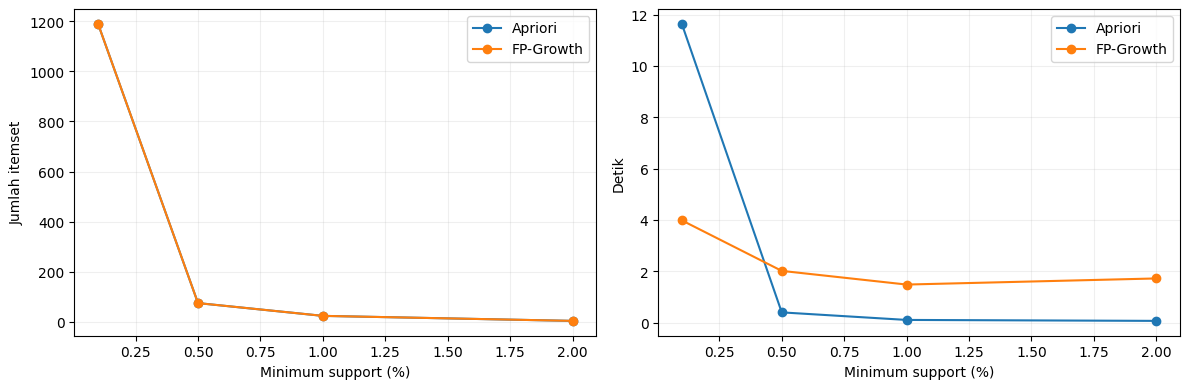

In [8]:
comparison = mining_summary.copy()
comparison["rules"] = comparison.apply(
    lambda row: len(generate_rules(mining[(row["algorithm"], row["min_support"])], len(author_tx))), axis=1
)
checks = []
for support in SUPPORTS:
    a = mining[("Apriori", support)]
    f = mining[("FP-Growth", support)]
    a_map = {frozenset(items): val for items, val in zip(a.itemsets, a.support)}
    f_map = {frozenset(items): val for items, val in zip(f.itemsets, f.support)}
    same = a_map.keys() == f_map.keys() and all(abs(a_map[k] - f_map[k]) < 1e-10 for k in a_map)
    checks.append({"min_support": support, "same_itemsets_and_support": same})
    if not same: print("PERIKSA PERBEDAAN:", support)
display(comparison, pd.DataFrame(checks))
assert all(x["same_itemsets_and_support"] for x in checks), "Apriori dan FP-Growth berbeda; periksa input dan versi library"
comparison.to_csv(RESULTS / "task6_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alg, part in comparison.groupby("algorithm"):
    axes[0].plot(part.min_support * 100, part.itemsets, marker="o", label=alg)
    axes[1].plot(part.min_support * 100, part.seconds, marker="o", label=alg)
axes[0].set(xlabel="Minimum support (%)", ylabel="Jumlah itemset")
axes[1].set(xlabel="Minimum support (%)", ylabel="Detik")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## Bagian E — Temporal Association Analysis

Gunakan transaksi penulis–tahun, kelompokkan berdasarkan tahun. Support dihitung ulang dengan penyebut jumlah transaksi **masing-masing periode**. Periode 2024–2025 hanya dua tahun, jadi bandingkan support/rate dan jumlah transaksi, bukan jumlah mentah saja. Ambang support dan confidence dibuat sama antarperiode.

In [9]:
PERIODS = {"2015–2017": (2015, 2017), "2018–2020": (2018, 2020),
           "2021–2023": (2021, 2023), "2024–2025": (2024, 2025)}
temporal_itemsets, temporal_rules, temporal_summary = {}, {}, []
for period, (start, end) in PERIODS.items():
    subset = author_year_tx.loc[author_year_tx.year.between(start, end)]
    matrix = sparse_transactions(subset["items"], TEMPORAL_SUPPORT)
    found, seconds = mine(matrix, "FP-Growth", TEMPORAL_SUPPORT)
    rules = generate_rules(found, len(subset))
    temporal_itemsets[period] = found
    temporal_rules[period] = rules
    temporal_summary.append({"period": period, "transactions": len(subset),
                             "itemsets": len(found), "rules": len(rules), "seconds": seconds})
    print(period, "| transaksi:", len(subset), "| itemsets:", len(found), "| rules:", len(rules))
    display(itemset_table(found.sort_values("support", ascending=False).head(10)))
    if not rules.empty:
        display(rule_table(rules.sort_values("lift", ascending=False).head(10))
                [["antecedents", "consequents", "support", "confidence", "lift"]])
    itemset_table(found).to_csv(RESULTS / f"temporal_itemsets_{start}_{end}.csv", index=False)
    rule_table(rules).to_csv(RESULTS / f"temporal_rules_{start}_{end}.csv", index=False)
display(pd.DataFrame(temporal_summary))

rule_sets = {period: {(frozenset(a), frozenset(c)) for a, c in zip(r.antecedents, r.consequents)}
             for period, r in temporal_rules.items()}
persistent = set.intersection(*rule_sets.values()) if rule_sets else set()
print("Rule yang muncul di semua periode:", len(persistent))
for a, c in sorted(persistent, key=lambda pair: (sorted(pair[0]), sorted(pair[1])))[:20]:
    print(" | ".join(sorted(a)), "→", " | ".join(sorted(c)))
for period, ruleset in rule_sets.items():
    others = set.union(*(v for k, v in rule_sets.items() if k != period))
    print("Khusus", period, ":", len(ruleset - others), "rule")

/var/folders/xw/znbphpc573144kp2m756_r2c0000gp/T/ipykernel_31013/940000445.py:16: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  return pd.DataFrame.sparse.from_spmatrix(matrix, columns=columns)


2015–2017 | transaksi: 923143 | itemsets: 31 | rules: 0


,support,itemsets,size
4,0.018724,EMBC,1
16,0.014931,IGARSS,1
11,0.011181,ICC,1
10,0.010843,IECON,1
24,0.010747,ICASSP,1
13,0.009172,IROS,1
19,0.009052,GLOBECOM,1
17,0.008934,ICIP,1
12,0.008622,OFC,1
6,0.008181,CDC,1


/var/folders/xw/znbphpc573144kp2m756_r2c0000gp/T/ipykernel_31013/940000445.py:16: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  return pd.DataFrame.sparse.from_spmatrix(matrix, columns=columns)


2018–2020 | transaksi: 1081666 | itemsets: 31 | rules: 0


,support,itemsets,size
8,0.017750,IGARSS,1
3,0.016194,EMBC,1
24,0.013424,AAAI,1
18,0.013090,ICASSP,1
19,0.012557,NeurIPS,1
25,0.011308,CVPR,1
9,0.010213,IROS,1
10,0.009371,ICRA,1
14,0.008534,GLOBECOM,1
30,0.008365,IJCAI,1


... (4 outputs left out)

2024–2025 | transaksi: 887076 | itemsets: 47 | rules: 0


,support,itemsets,size
0,0.049307,NeurIPS,1
11,0.028960,AAAI,1
7,0.028122,ICLR,1
8,0.026708,CVPR,1
4,0.026646,ICML,1
2,0.023685,ICASSP,1
27,0.016404,IROS,1
38,0.015678,EMNLP,1
13,0.015464,ICRA,1
29,0.015327,IJCNN,1


,period,transactions,itemsets,rules,seconds
0,2015–2017,923143,31,0,0.462165
1,2018–2020,1081666,31,0,0.566245
2,2021–2023,1196939,36,0,0.651094
3,2024–2025,887076,47,0,0.630049


Rule yang muncul di semua periode: 0
Khusus 2015–2017 : 0 rule
Khusus 2018–2020 : 0 rule
Khusus 2021–2023 : 0 rule
Khusus 2024–2025 : 0 rule


In [10]:
# Bandingkan metrik rule yang bertahan pada semua periode.
comparison_rows = []
for period, rules in temporal_rules.items():
    for _, row in rules.iterrows():
        key = (frozenset(row.antecedents), frozenset(row.consequents))
        if key in persistent:
            comparison_rows.append({
                "period": period,
                "antecedents": " | ".join(sorted(row.antecedents)),
                "consequents": " | ".join(sorted(row.consequents)),
                "support": row.support, "confidence": row.confidence, "lift": row.lift,
            })
persistent_metrics = pd.DataFrame(comparison_rows)
if not persistent_metrics.empty:
    display(persistent_metrics.sort_values(["antecedents", "consequents", "period"]).head(40))
    persistent_metrics.to_csv(RESULTS / "temporal_persistent_rules.csv", index=False)
else:
    print("Tidak ada rule yang bertahan di semua periode pada ambang ini.")

Tidak ada rule yang bertahan di semua periode pada ambang ini.


**Interpretasi temporal:** rule yang hanya muncul pada satu periode bisa dipengaruhi support, ukuran periode, atau perubahan komposisi penulis. Periksa support/confidence/lift lintas periode sebelum menyebutnya tren baru atau pola yang hilang.

## Kesimpulan dan checklist laporan

Isi setelah seluruh sel selesai dijalankan:

1. Venue paling populer menurut publikasi dan menurut penulis unik: **[isi]**.
2. Apakah venue terpopuler juga punya asosiasi terkuat? Bandingkan peringkat publikasi dengan lift: **[isi]**.
3. Kombinasi venue paling sering muncul bersama: **[isi support dan jumlah transaksi]**.
4. Rule dengan lift tertinggi dan maknanya: **[isi]**.
5. Perbedaan author-based dan author-year-based: **[isi berdasarkan statistik dan eksperimen]**.
6. Algoritma yang lebih sesuai berdasarkan itemset identik, waktu, dan keterbatasan mesin: **[isi]**.
7. Insight utama serta keterbatasan dataset dan normalisasi: **[isi]**.

Sertakan pada laporan: sumber/DOI snapshot, tanggal unduh, jumlah record awal dan akhir, aturan alias, versi library, spesifikasi mesin, semua parameter, visualisasi, dan penjelasan hasil. File tabel tersimpan di `results/`.

In [11]:
import platform
metadata = {
    "snapshot_url": SNAPSHOT_URL, "download_date": DOWNLOAD_DATE,
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "years": [YEAR_MIN, YEAR_MAX], "support_thresholds": SUPPORTS,
    "minimum_confidence": MIN_CONFIDENCE, "temporal_support": TEMPORAL_SUPPORT,
    "venue_aliases": VENUE_ALIASES, "python": platform.python_version(),
    "pandas": pd.__version__, "numpy": np.__version__, "mlxtend": mlxtend.__version__,
}
(RESULTS / "run_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print("Metadata disimpan di", RESULTS / "run_metadata.json")
con.close()

Metadata disimpan di /Users/hello/Documents/Folder Surya/Kuliah/Semester 7/Penambangan Data/Tugas Besar Data Mining/results/run_metadata.json
